<a href="https://colab.research.google.com/github/nr868848-stack/E-commerce-_customer_Segmentation_RFM_Analysis/blob/main/E_commerce_Customer_Segmentation_RFM_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# PROJECT: ADVANCED E-COMMERCE SALES ANALYSIS
# STEP 1: IMPORT REQUIRED LIBRARIES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from datetime import datetime, timedelta
import warnings

warnings.filterwarnings("ignore")

np.random.seed(42)

print("=" * 60)
print("ADVANCED E-COMMERCE SALES ANALYSIS PROJECT")
print("=" * 60)

print("NumPy Version:", np.__version__)
print("Pandas Version:", pd.__version__)
print("All libraries imported successfully!")

ADVANCED E-COMMERCE SALES ANALYSIS PROJECT
NumPy Version: 2.1.3
Pandas Version: 2.2.3
All libraries imported successfully!


In [ ]:
# ============================================================
# STEP 2: CREATE E-COMMERCE DATASET
# ============================================================

number_of_orders = 5000

product_names = [
    "Laptop",
    "Smartphone",
    "Headphones",
    "Keyboard",
    "Mouse",
    "Monitor",
    "Tablet",
    "Smartwatch",
    "Printer",
    "Speaker"
]

product_categories = [
    "Electronics",
    "Accessories",
    "Computers",
    "Mobile Devices",
    "Audio"
]

regions = [
    "North",
    "South",
    "East",
    "West",
    "Central"
]

payment_methods = [
    "UPI",
    "Credit Card",
    "Debit Card",
    "Cash",
    "Net Banking"
]

sales_channels = [
    "Website",
    "Mobile App",
    "Marketplace"
]

start_date = datetime(2025, 1, 1)

order_dates = [
    start_date + timedelta(
        days=int(x)
    )
    for x in np.random.randint(
        0, 600, number_of_orders
    )
]

product_category_map = {
    "Laptop": "Computers",
    "Smartphone": "Mobile Devices",
    "Headphones": "Audio",
    "Keyboard": "Accessories",
    "Mouse": "Accessories",
    "Monitor": "Computers",
    "Tablet": "Mobile Devices",
    "Smartwatch": "Mobile Devices",
    "Printer": "Accessories",
    "Speaker": "Audio"
}

base_price_map = {
    "Laptop": 55000,
    "Smartphone": 25000,
    "Headphones": 2500,
    "Keyboard": 1200,
    "Mouse": 700,
    "Monitor": 12000,
    "Tablet": 18000,
    "Smartwatch": 5000,
    "Printer": 8000,
    "Speaker": 3000
}

orders = pd.DataFrame({
    "Order_ID": range(
        100001,
        100001 + number_of_orders
    ),

    "Order_Date": order_dates,

    "Customer_ID": np.random.randint(
        1001, 2001, number_of_orders
    ),

    "Product": np.random.choice(
        product_names,
        number_of_orders
    ),

    "Region": np.random.choice(
        regions,
        number_of_orders
    ),

    "Payment_Method": np.random.choice(
        payment_methods,
        number_of_orders
    ),

    "Sales_Channel": np.random.choice(
        sales_channels,
        number_of_orders
    ),

    "Quantity": np.random.randint(
        1, 6, number_of_orders
    ),

    "Discount_Percent": np.random.choice(
        [0, 5, 10, 15, 20],
        number_of_orders
    )
})

orders["Category"] = orders["Product"].map(
    product_category_map
)

orders["Unit_Price"] = orders["Product"].map(
    base_price_map
)

# Small price variations
price_variation = np.random.uniform(
    0.90, 1.10, number_of_orders
)

orders["Unit_Price"] = (
    orders["Unit_Price"] * price_variation
).round(2)

# Revenue after discount
orders["Sales"] = (
    orders["Quantity"]
    * orders["Unit_Price"]
    * (1 - orders["Discount_Percent"] / 100)
).round(2)

# Estimated product cost
orders["Cost"] = (
    orders["Quantity"]
    * orders["Unit_Price"]
    * np.random.uniform(
        0.55, 0.80, number_of_orders
    )
).round(2)

# Profit
orders["Profit"] = (
    orders["Sales"] - orders["Cost"]
).round(2)

print("Dataset created successfully!")
print("Total Orders:", len(orders))
print(
    "Unique Customers:",
    orders["Customer_ID"].nunique()
)

display(orders.head(10))

Dataset created successfully!
Total Orders: 5000
Unique Customers: 989


,Order_ID,Order_Date,Customer_ID,Product,Region,Payment_Method,Sales_Channel,Quantity,Discount_Percent,Category,Unit_Price,Sales,Cost,Profit
0,100001,2025-04-13,1179,Headphones,Central,Debit Card,Website,2,15,Audio,2265.35,3851.10,3116.51,734.59
1,100002,2026-03-12,1631,Mouse,South,UPI,Marketplace,5,20,Accessories,748.87,2995.48,2579.68,415.80
2,100003,2025-09-28,1433,Keyboard,Central,UPI,Mobile App,3,0,Accessories,1172.13,3516.39,2383.20,1133.19
3,100004,2025-04-17,1265,Smartwatch,North,Net Banking,Website,2,0,Mobile Devices,4618.24,9236.48,5921.33,3315.15
4,100005,2025-03-13,1954,Keyboard,East,UPI,Marketplace,2,20,Accessories,1216.20,1945.92,1609.38,336.54
5,100006,2025-01-21,1429,Smartwatch,South,UPI,Website,1,10,Mobile Devices,5452.36,4907.12,3152.06,1755.06
6,100007,2025-05-02,1662,Monitor,East,Debit Card,Marketplace,1,15,Computers,12102.03,10286.73,9180.93,1105.80
7,100008,2026-04-12,1416,Mouse,North,Debit Card,Mobile App,2,0,Accessories,726.13,1452.26,1121.58,330.68
8,100009,2025-08-03,1453,Keyboard,South,Cash,Website,5,15,Accessories,1275.94,5422.75,4730.98,691.77
9,100010,2025-11-27,1727,Keyboard,East,Debit Card,Mobile App,3,10,Accessories,1271.84,3433.97,2655.21,778.76


In [ ]:
# ============================================================
# STEP 3: DATASET UNDERSTANDING
# ============================================================

print("DATASET SHAPE")
print(orders.shape)

print("\nCOLUMN NAMES")
print(orders.columns.tolist())

print("\nDATA TYPES")
print(orders.dtypes)

print("\nDATASET INFORMATION")
orders.info()

print("\nSTATISTICAL SUMMARY")
display(orders.describe())

print("\nFIRST 10 RECORDS")
display(orders.head(10))

print("\nLAST 5 RECORDS")
display(orders.tail())

DATASET SHAPE
(5000, 14)

COLUMN NAMES
['Order_ID', 'Order_Date', 'Customer_ID', 'Product', 'Region', 'Payment_Method', 'Sales_Channel', 'Quantity', 'Discount_Percent', 'Category', 'Unit_Price', 'Sales', 'Cost', 'Profit']

DATA TYPES
Order_ID                     int64
Order_Date          datetime64[ns]
Customer_ID                  int64
Product                     object
Region                      object
Payment_Method              object
Sales_Channel               object
Quantity                     int64
Discount_Percent             int64
Category                    object
Unit_Price                 float64
Sales                      float64
Cost                       float64
Profit                     float64
dtype: object

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Order_ID          500

,Order_ID,Order_Date,Customer_ID,Quantity,Discount_Percent,Unit_Price,Sales,Cost,Profit
count,5000.000000,5000,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,102500.500000,2025-10-27 08:53:22.560000256,1498.44900,3.051800,9.993000,12955.561720,35655.771768,26711.495702,8944.276066
min,100001.000000,2025-01-01 00:00:00,1001.00000,1.000000,0.000000,630.050000,504.040000,362.340000,1.290000
25%,101250.750000,2025-05-31 00:00:00,1241.00000,2.000000,5.000000,2505.887500,4906.950000,3702.940000,977.505000
50%,102500.500000,2025-10-28 00:00:00,1501.50000,3.000000,10.000000,5464.110000,14199.910000,10620.600000,3263.260000
75%,103750.250000,2026-03-26 00:00:00,1749.00000,4.000000,15.000000,17864.637500,43938.412500,32842.330000,9768.725000
max,105000.000000,2026-08-23 00:00:00,2000.00000,5.000000,20.000000,60481.800000,302327.100000,233624.210000,127453.250000
std,1443.520003,NaN,288.85402,1.408373,7.109505,15905.994718,51993.076548,38970.059011,14792.568509



FIRST 10 RECORDS


,Order_ID,Order_Date,Customer_ID,Product,Region,Payment_Method,Sales_Channel,Quantity,Discount_Percent,Category,Unit_Price,Sales,Cost,Profit
0,100001,2025-04-13,1179,Headphones,Central,Debit Card,Website,2,15,Audio,2265.35,3851.10,3116.51,734.59
1,100002,2026-03-12,1631,Mouse,South,UPI,Marketplace,5,20,Accessories,748.87,2995.48,2579.68,415.80
2,100003,2025-09-28,1433,Keyboard,Central,UPI,Mobile App,3,0,Accessories,1172.13,3516.39,2383.20,1133.19
3,100004,2025-04-17,1265,Smartwatch,North,Net Banking,Website,2,0,Mobile Devices,4618.24,9236.48,5921.33,3315.15
4,100005,2025-03-13,1954,Keyboard,East,UPI,Marketplace,2,20,Accessories,1216.20,1945.92,1609.38,336.54
5,100006,2025-01-21,1429,Smartwatch,South,UPI,Website,1,10,Mobile Devices,5452.36,4907.12,3152.06,1755.06
6,100007,2025-05-02,1662,Monitor,East,Debit Card,Marketplace,1,15,Computers,12102.03,10286.73,9180.93,1105.80
7,100008,2026-04-12,1416,Mouse,North,Debit Card,Mobile App,2,0,Accessories,726.13,1452.26,1121.58,330.68
8,100009,2025-08-03,1453,Keyboard,South,Cash,Website,5,15,Accessories,1275.94,5422.75,4730.98,691.77
9,100010,2025-11-27,1727,Keyboard,East,Debit Card,Mobile App,3,10,Accessories,1271.84,3433.97,2655.21,778.76



LAST 5 RECORDS


,Order_ID,Order_Date,Customer_ID,Product,Region,Payment_Method,Sales_Channel,Quantity,Discount_Percent,Category,Unit_Price,Sales,Cost,Profit
4995,104996,2026-07-21,1972,Smartphone,West,UPI,Website,4,0,Mobile Devices,22733.75,90935.00,72000.36,18934.64
4996,104997,2025-05-24,1677,Mouse,West,Credit Card,Website,1,5,Accessories,678.12,644.21,377.00,267.21
4997,104998,2026-02-16,1992,Monitor,East,Net Banking,Website,4,20,Computers,12355.00,39536.00,33126.23,6409.77
4998,104999,2025-08-12,1139,Speaker,East,Credit Card,Mobile App,4,0,Audio,3011.22,12044.88,7438.57,4606.31
4999,105000,2025-08-08,1276,Keyboard,East,Net Banking,Marketplace,5,15,Accessories,1248.70,5306.98,4588.79,718.19


In [ ]:
# ============================================================
# STEP 4: DATA QUALITY CHECK
# ============================================================

print("MISSING VALUES")
print(orders.isnull().sum())

print("\nDUPLICATE ROWS")
print(orders.duplicated().sum())

print("\nUNIQUE VALUES PER COLUMN")
print(orders.nunique())

print("\nNEGATIVE SALES RECORDS")
print((orders["Sales"] < 0).sum())

print("\nNEGATIVE PROFIT RECORDS")
print((orders["Profit"] < 0).sum())

print("\nINVALID QUANTITY RECORDS")
print((orders["Quantity"] <= 0).sum())

MISSING VALUES
Order_ID            0
Order_Date          0
Customer_ID         0
Product             0
Region              0
Payment_Method      0
Sales_Channel       0
Quantity            0
Discount_Percent    0
Category            0
Unit_Price          0
Sales               0
Cost                0
Profit              0
dtype: int64

DUPLICATE ROWS
0

UNIQUE VALUES PER COLUMN
Order_ID            5000
Order_Date           600
Customer_ID          989
Product               10
Region                 5
Payment_Method         5
Sales_Channel          3
Quantity               5
Discount_Percent       5
Category               4
Unit_Price          4978
Sales               4997
Cost                4994
Profit              4984
dtype: int64

NEGATIVE SALES RECORDS
0

NEGATIVE PROFIT RECORDS
0

INVALID QUANTITY RECORDS
0


In [ ]:
# ============================================================
# STEP 5: DATA CLEANING AND FEATURE ENGINEERING
# ============================================================

df = orders.copy()

# Convert date column to datetime
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    errors="coerce"
)

# Remove duplicate order IDs
df = df.drop_duplicates(
    subset=["Order_ID"]
)

# Remove records with essential missing values
df = df.dropna(
    subset=[
        "Order_ID",
        "Order_Date",
        "Customer_ID",
        "Sales",
        "Cost",
        "Profit"
    ]
)

# Keep valid business records
df = df[
    (df["Quantity"] > 0)
    & (df["Unit_Price"] > 0)
    & (df["Sales"] >= 0)
].copy()

# Date-based features
df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.month

df["Month_Name"] = df[
    "Order_Date"
].dt.month_name()

df["Quarter"] = df[
    "Order_Date"
].dt.quarter

df["Day_Name"] = df[
    "Order_Date"
].dt.day_name()

# Profit margin percentage
df["Profit_Margin_Percent"] = np.where(
    df["Sales"] != 0,
    df["Profit"] / df["Sales"] * 100,
    0
)

# Order value categories
df["Sales_Category"] = pd.cut(
    df["Sales"],
    bins=[-0.01, 5000, 20000, 50000, np.inf],
    labels=[
        "Low Value",
        "Medium Value",
        "High Value",
        "Premium Value"
    ]
)

print("Data cleaning completed!")
print("Clean dataset shape:", df.shape)

display(df.head())

Data cleaning completed!
Clean dataset shape: (5000, 21)


,Order_ID,Order_Date,Customer_ID,Product,Region,Payment_Method,Sales_Channel,Quantity,Discount_Percent,Category,...,Sales,Cost,Profit,Year,Month,Month_Name,Quarter,Day_Name,Profit_Margin_Percent,Sales_Category
0,100001,2025-04-13,1179,Headphones,Central,Debit Card,Website,2,15,Audio,...,3851.10,3116.51,734.59,2025,4,April,2,Sunday,19.074810,Low Value
1,100002,2026-03-12,1631,Mouse,South,UPI,Marketplace,5,20,Accessories,...,2995.48,2579.68,415.80,2026,3,March,1,Thursday,13.880914,Low Value
2,100003,2025-09-28,1433,Keyboard,Central,UPI,Mobile App,3,0,Accessories,...,3516.39,2383.20,1133.19,2025,9,September,3,Sunday,32.225948,Low Value
3,100004,2025-04-17,1265,Smartwatch,North,Net Banking,Website,2,0,Mobile Devices,...,9236.48,5921.33,3315.15,2025,4,April,2,Thursday,35.891920,Medium Value
4,100005,2025-03-13,1954,Keyboard,East,UPI,Marketplace,2,20,Accessories,...,1945.92,1609.38,336.54,2025,3,March,1,Thursday,17.294647,Low Value


In [ ]:
# ==========================================
# STEP 6: BUSINESS KPI ANALYSIS
# ==========================================

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order_ID"].nunique()
total_customers = df["Customer_ID"].nunique()
average_order_value = total_sales / total_orders
profit_margin = (total_profit / total_sales) * 100

print("=" * 45)
print("E-COMMERCE BUSINESS PERFORMANCE")
print("=" * 45)

print(f"Total Sales: Rs. {total_sales:,.2f}")
print(f"Total Profit: Rs. {total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Unique Customers: {total_customers:,}")
print(f"Average Order Value: Rs. {average_order_value:,.2f}")
print(f"Profit Margin: {profit_margin:.2f}%")

E-COMMERCE BUSINESS PERFORMANCE
Total Sales: Rs. 178,278,858.84
Total Profit: Rs. 44,721,380.33
Total Orders: 5,000
Unique Customers: 989
Average Order Value: Rs. 35,655.77
Profit Margin: 25.09%


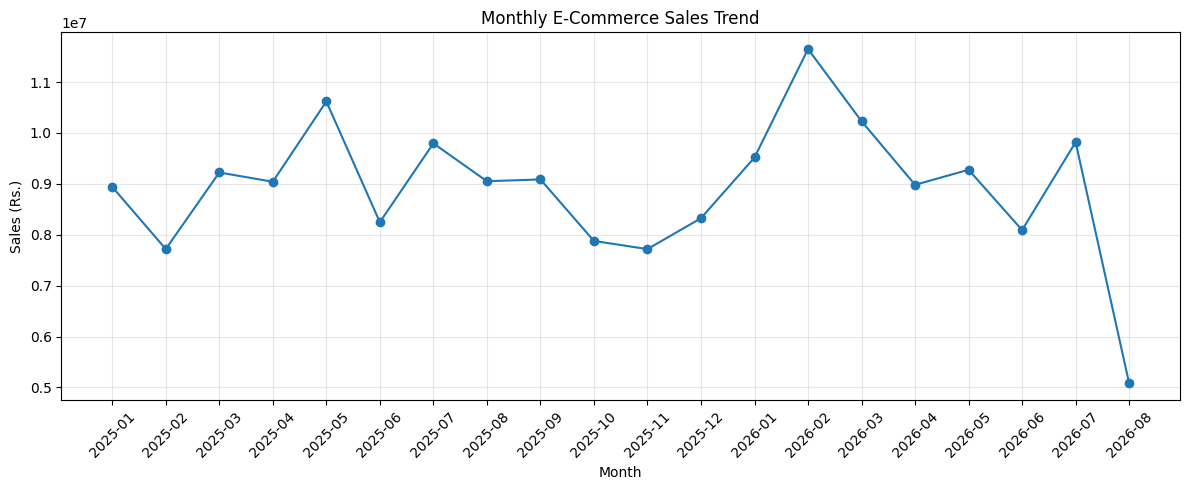

,Order_Date,Total_Sales
0,2025-01,8939350.11
1,2025-02,7718551.31
2,2025-03,9222383.54
3,2025-04,9040887.83
4,2025-05,10618334.63
5,2025-06,8246927.50
6,2025-07,9794464.96
7,2025-08,9050953.94
8,2025-09,9086440.00
9,2025-10,7877554.86


In [ ]:
# ==========================================
# STEP 7: MONTHLY SALES TREND
# ==========================================

monthly_sales = (
    df.groupby(df["Order_Date"].dt.to_period("M"))["Sales"]
    .sum()
    .sort_index()
)

monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly E-Commerce Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (Rs.)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

display(monthly_sales.reset_index(name="Total_Sales"))

,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders
Product,,,,
Laptop,78182690.29,19767212.95,1583,505
Smartphone,31825702.96,7946582.73,1410,472
Tablet,23336014.71,5774190.83,1438,494
Monitor,16344223.76,4060422.16,1512,505
Printer,11324462.01,2831667.71,1569,511
Smartwatch,6838828.91,1738257.77,1518,501
Speaker,4386190.36,1123860.96,1621,516
Headphones,3427131.98,819574.03,1527,497
Keyboard,1643122.51,409705.42,1535,502


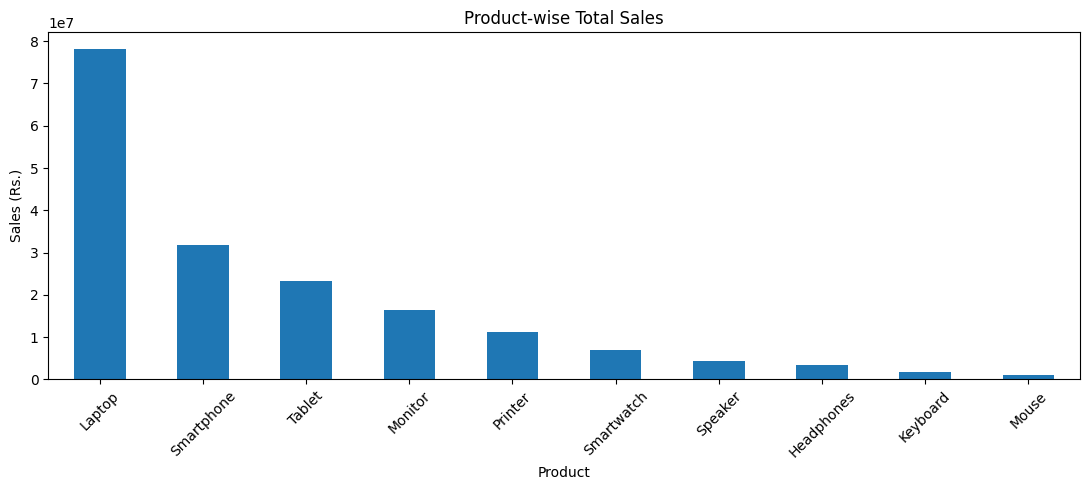

In [ ]:
# ==========================================
# STEP 8: PRODUCT PERFORMANCE ANALYSIS
# ==========================================

product_performance = (
    df.groupby("Product")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Number_of_Orders=("Order_ID", "nunique")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(product_performance.round(2))

product_performance["Total_Sales"].plot(
    kind="bar",
    figsize=(11, 5),
    title="Product-wise Total Sales"
)

plt.xlabel("Product")
plt.ylabel("Sales (Rs.)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

,Sales,Profit,Orders,Profit_Margin_Percent
Category,,,,
Computers,94526914.05,23827635.11,1010,25.21
Mobile Devices,62000546.58,15459031.33,1467,24.93
Accessories,13938075.87,3491278.90,1510,25.05
Audio,7813322.34,1943434.99,1013,24.87


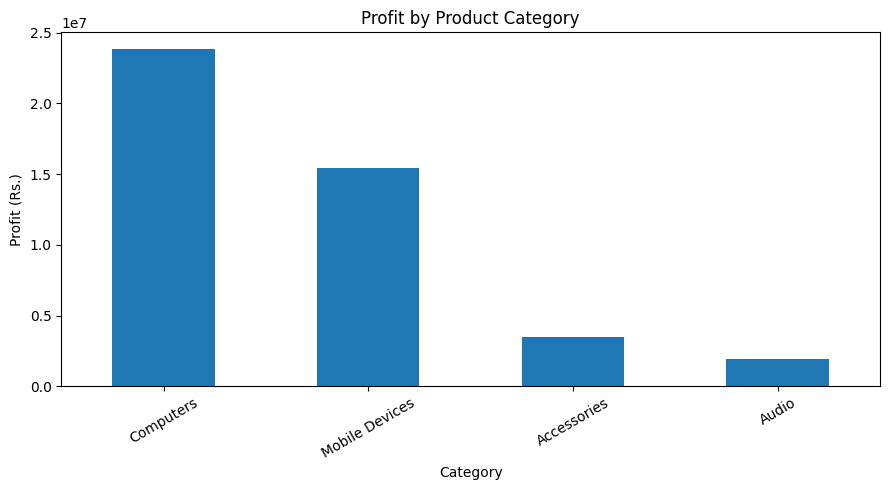

In [ ]:
# ==========================================
# STEP 9: CATEGORY PROFIT ANALYSIS
# ==========================================

category_analysis = (
    df.groupby("Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Orders=("Order_ID", "nunique")
    )
    .sort_values("Profit", ascending=False)
)

category_analysis["Profit_Margin_Percent"] = (
    category_analysis["Profit"]
    / category_analysis["Sales"]
    * 100
)

display(category_analysis.round(2))

category_analysis["Profit"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Profit by Product Category"
)

plt.xlabel("Category")
plt.ylabel("Profit (Rs.)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

,Total_Sales,Total_Profit,Total_Orders,Average_Discount
Region,,,,
South,37519464.48,9305603.04,1038,10.14
Central,37424052.83,9117949.61,1012,10.11
West,36137498.50,9367920.14,984,10.07
North,34688550.87,8531620.32,994,9.66
East,32509292.16,8398287.22,972,9.97


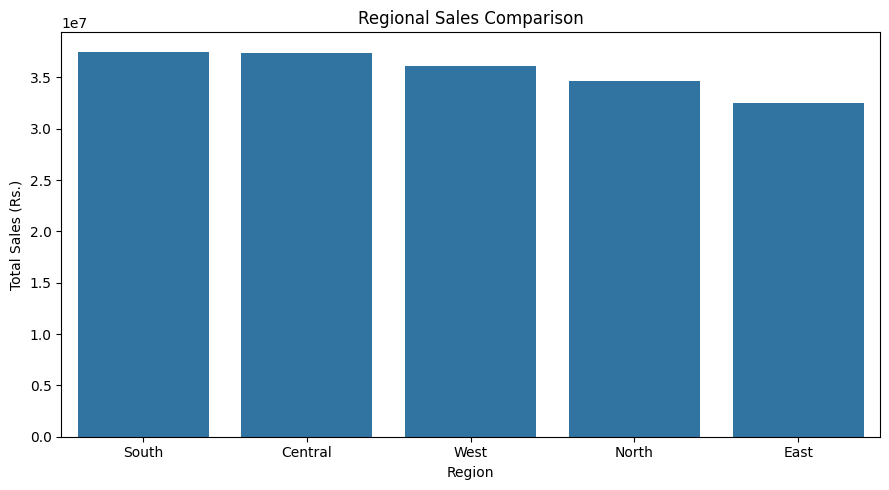

In [ ]:
# ==========================================
# STEP 10: REGIONAL SALES ANALYSIS
# ==========================================

region_analysis = (
    df.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order_ID", "nunique"),
        Average_Discount=("Discount_Percent", "mean")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(region_analysis.round(2))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=region_analysis.reset_index(),
    x="Region",
    y="Total_Sales"
)

plt.title("Regional Sales Comparison")
plt.xlabel("Region")
plt.ylabel("Total Sales (Rs.)")
plt.tight_layout()
plt.show()

,Total_Sales,Total_Profit,Average_Order_Value,Number_of_Orders
Discount_Percent,,,,
0,39908574.37,13012880.46,39474.36,1011
5,39245401.43,11197325.69,39050.15,1005
10,33613792.37,8427347.34,34195.11,983
15,34642755.23,7111539.69,35277.75,982
20,30868335.44,4972287.15,30292.77,1019


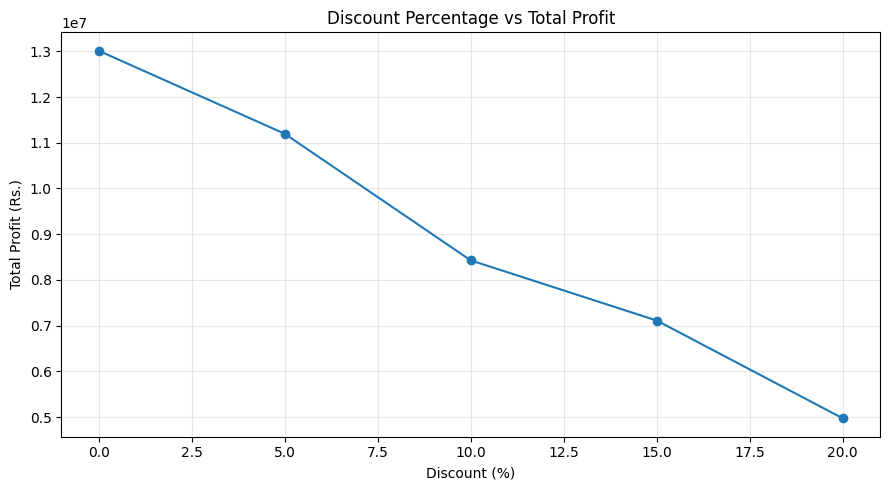

In [ ]:
# ==========================================
# STEP 11: DISCOUNT IMPACT ANALYSIS
# ==========================================

discount_analysis = (
    df.groupby("Discount_Percent")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Order_Value=("Sales", "mean"),
        Number_of_Orders=("Order_ID", "count")
    )
    .sort_index()
)

display(discount_analysis.round(2))

plt.figure(figsize=(9, 5))

plt.plot(
    discount_analysis.index,
    discount_analysis["Total_Profit"],
    marker="o"
)

plt.title("Discount Percentage vs Total Profit")
plt.xlabel("Discount (%)")
plt.ylabel("Total Profit (Rs.)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

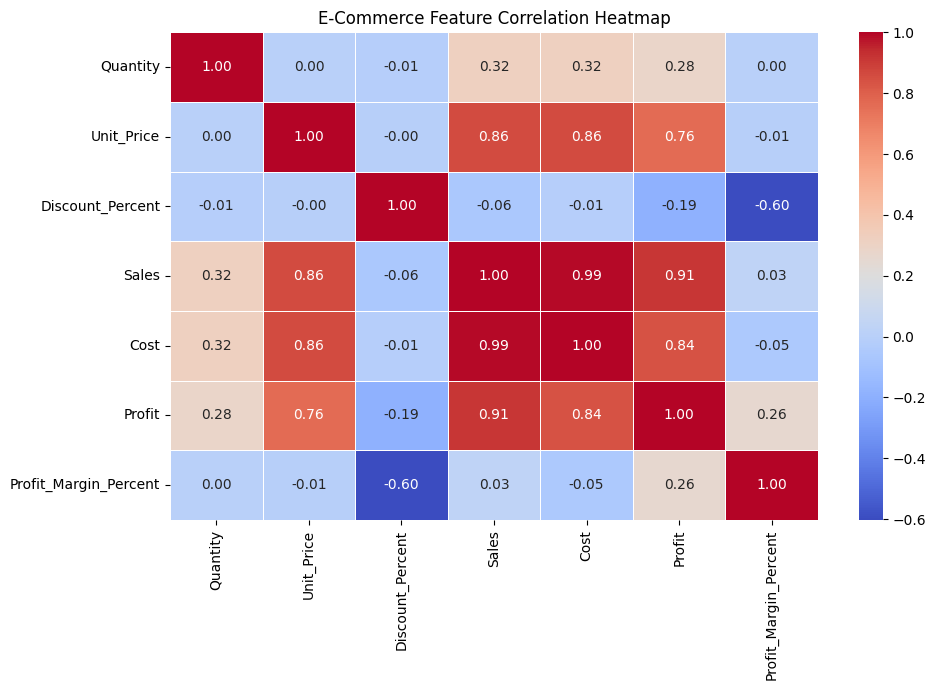

In [ ]:
# ==========================================
# STEP 12: CORRELATION ANALYSIS
# ==========================================

numeric_features = [
    "Quantity",
    "Unit_Price",
    "Discount_Percent",
    "Sales",
    "Cost",
    "Profit",
    "Profit_Margin_Percent"
]

correlation_matrix = df[numeric_features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("E-Commerce Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [ ]:
# STEP 13: OUTLIER DETECTION

Q1 = df["Sales"].quantile(0.25)
Q3 = df["Sales"].quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

df["Sales_Outlier"] = (
    (df["Sales"] < lower_limit) |
    (df["Sales"] > upper_limit)
)

print("Total Orders:", len(df))
print("Sales Outliers:", df["Sales_Outlier"].sum())

print("\nOrders with unusual sales:")
display(
    df[df["Sales_Outlier"]]
    [["Order_ID", "Product", "Sales", "Profit"]]
    .head(10)
)

Total Orders: 5000
Sales Outliers: 434

Orders with unusual sales:


,Order_ID,Product,Sales,Profit
22,100023,Laptop,163132.60,30294.22
30,100031,Laptop,186708.04,47117.72
32,100033,Laptop,143540.16,55183.15
33,100034,Laptop,149520.86,11867.27
42,100043,Laptop,200840.56,17253.20
43,100044,Laptop,192700.98,48874.70
46,100047,Laptop,139977.86,5631.64
63,100064,Smartphone,130856.40,37557.89
66,100067,Laptop,202053.16,83192.69
70,100071,Smartphone,111667.54,22895.32


,Product,Total_Sales,Sales_Percentage,Cumulative_Percentage
2,Laptop,78182690.29,43.85,43.85
6,Smartphone,31825702.96,17.85,61.71
9,Tablet,23336014.71,13.09,74.80
3,Monitor,16344223.76,9.17,83.96
5,Printer,11324462.01,6.35,90.32
7,Smartwatch,6838828.91,3.84,94.15
8,Speaker,4386190.36,2.46,96.61
0,Headphones,3427131.98,1.92,98.53
1,Keyboard,1643122.51,0.92,99.46
4,Mouse,970491.35,0.54,100.00


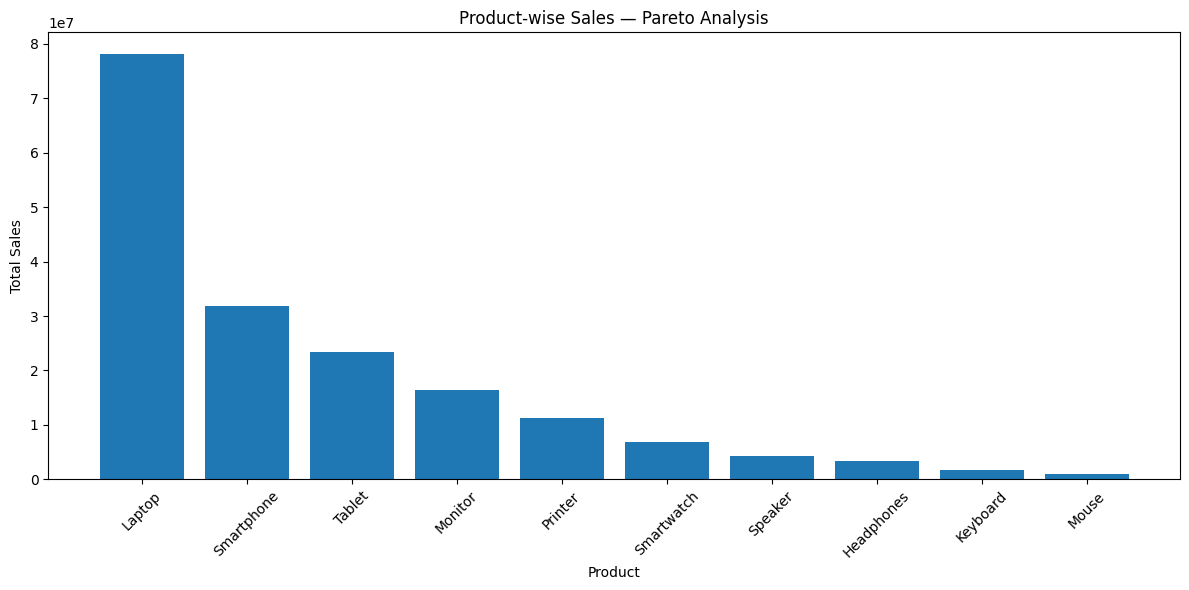

In [ ]:
# STEP 14: PARETO ANALYSIS

pareto = (
    df.groupby("Product", as_index=False)
      .agg(Total_Sales=("Sales", "sum"))
      .sort_values("Total_Sales", ascending=False)
)

pareto["Sales_Percentage"] = (
    pareto["Total_Sales"] / pareto["Total_Sales"].sum()
) * 100

pareto["Cumulative_Percentage"] = (
    pareto["Sales_Percentage"].cumsum()
)

display(pareto.round(2))

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.bar(pareto["Product"], pareto["Total_Sales"])
plt.xticks(rotation=45)
plt.title("Product-wise Sales — Pareto Analysis")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

In [ ]:
# STEP 15: CUSTOMER ANALYSIS

customer_analysis = (
    df.groupby("Customer_ID", as_index=False)
      .agg(
          Total_Orders=("Order_ID", "nunique"),
          Total_Spending=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Average_Order_Value=("Sales", "mean"),
          Average_Discount=("Discount_Percent", "mean")
      )
)

customer_analysis = customer_analysis.sort_values(
    "Total_Spending", ascending=False
)

print("Total Unique Customers:", len(customer_analysis))
print("\nTop 10 Customers by Spending:")

display(customer_analysis.head(10).round(2))

Total Unique Customers: 989

Top 10 Customers by Spending:


,Customer_ID,Total_Orders,Total_Spending,Total_Profit,Average_Order_Value,Average_Discount
961,1973,10,750049.12,208060.57,75004.91,8.00
699,1708,8,738332.68,207899.89,92291.58,12.50
685,1694,7,688804.69,121912.25,98400.67,12.14
550,1557,7,676959.51,180698.62,96708.50,9.29
373,1379,9,651705.31,209471.67,72411.70,9.44
861,1871,10,633674.18,167717.52,63367.42,11.50
166,1171,7,622750.05,121777.81,88964.29,15.71
688,1697,9,622112.51,140102.37,69123.61,11.11
93,1095,4,621679.48,152735.65,155419.87,8.75
398,1404,5,610950.28,214997.43,122190.06,8.00


In [ ]:
# STEP 16: RFM CUSTOMER SEGMENTATION

import pandas as pd
import numpy as np

# Analysis date: dataset ki last date ke agle din
snapshot_date = df["Order_Date"].max() + pd.Timedelta(days=1)

# Customer-wise RFM metrics
rfm = df.groupby("Customer_ID").agg(
    Recency=("Order_Date", lambda x: (snapshot_date - x.max()).days),
    Frequency=("Order_ID", "nunique"),
    Monetary=("Sales", "sum")
).reset_index()

# Customer scores: 1 se 4 tak
# Rank use karne se repeated values hone par bhi scoring ho sakegi
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first", ascending=True),
    4, labels=[4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4, labels=[1, 2, 3, 4]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4, labels=[1, 2, 3, 4]
).astype(int)

# Total RFM score
rfm["RFM_Score"] = (
    rfm["R_Score"] + rfm["F_Score"] + rfm["M_Score"]
)

# Simple customer segments
def assign_segment(row):
    if row["RFM_Score"] >= 10:
        return "Best Customers"
    elif row["RFM_Score"] >= 8:
        return "Loyal / Potential Customers"
    elif row["R_Score"] <= 2:
        return "At Risk Customers"
    else:
        return "Regular Customers"

rfm["Customer_Segment"] = rfm.apply(assign_segment, axis=1)

print("Total Customers:", len(rfm))
print("\nCustomer Segment Counts:")

display(
    rfm["Customer_Segment"]
    .value_counts()
    .rename_axis("Customer_Segment")
    .reset_index(name="Number_of_Customers")
)

print("\nSample RFM Results:")
display(rfm.head(10))

Total Customers: 989

Customer Segment Counts:


,Customer_Segment,Number_of_Customers
0,At Risk Customers,354
1,Best Customers,259
2,Loyal / Potential Customers,249
3,Regular Customers,127



Sample RFM Results:


,Customer_ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Customer_Segment
0,1001,145,8,346935.81,2,4,4,10,Best Customers
1,1002,117,5,223936.31,2,2,3,7,At Risk Customers
2,1003,21,3,176677.62,4,1,3,8,Loyal / Potential Customers
3,1004,194,3,210908.48,1,1,3,5,At Risk Customers
4,1005,300,1,23238.98,1,1,1,3,At Risk Customers
5,1006,233,3,129095.90,1,1,2,4,At Risk Customers
6,1007,145,8,379613.88,2,4,4,10,Best Customers
7,1008,24,3,31105.00,4,1,1,6,Regular Customers
8,1009,287,5,300284.33,1,2,4,7,At Risk Customers
9,1010,183,5,278164.52,1,2,4,7,At Risk Customers


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


CUSTOMER SEGMENT REVENUE ANALYSIS

Total Revenue by Customer Segment:
--------------------------------------------------
Customer_Segment
Best Customers                 84273668.41
Loyal / Potential Customers    48796890.52
At Risk Customers              36786926.45
Regular Customers               8421373.46
Name: Monetary, dtype: float64

Revenue Contribution Percentage:
--------------------------------------------------
Customer_Segment
Best Customers                 47.27
Loyal / Potential Customers    27.37
At Risk Customers              20.63
Regular Customers               4.72
Name: Monetary, dtype: float64


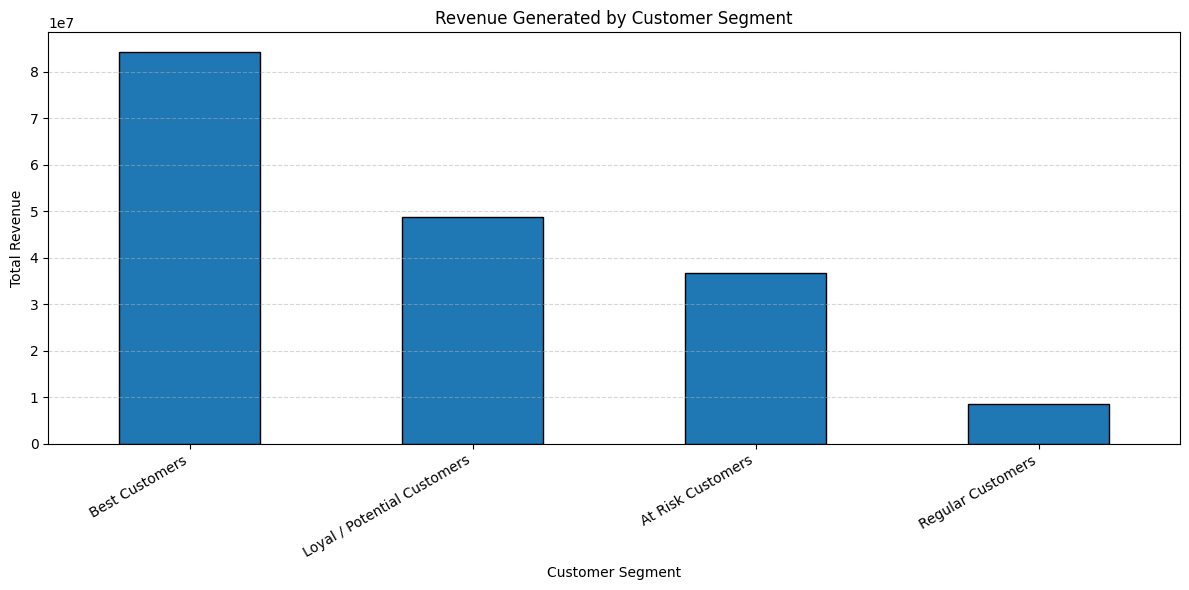

In [ ]:

# ==========================================
# STEP 19: CUSTOMER SEGMENT REVENUE ANALYSIS
# ==========================================

print("CUSTOMER SEGMENT REVENUE ANALYSIS")
print("=" * 50)

# Calculate revenue generated by each customer segment
segment_revenue = (
    rfm.groupby("Customer_Segment")["Monetary"]
    .sum()
    .sort_values(ascending=False)
)

print("\nTotal Revenue by Customer Segment:")
print("-" * 50)
print(segment_revenue.round(2))

# Calculate revenue contribution percentage
revenue_percentage = (
    segment_revenue / segment_revenue.sum()
) * 100

print("\nRevenue Contribution Percentage:")
print("-" * 50)
print(revenue_percentage.round(2))

# Visualize revenue by customer segment
plt.figure(figsize=(12, 6))

segment_revenue.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Revenue Generated by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Revenue")
plt.xticks(rotation=30, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:

# ==========================================
# STEP 20: AVERAGE CUSTOMER VALUE ANALYSIS
# ==========================================

segment_summary = rfm.groupby("Customer_Segment").agg(
    Total_Customers=("Customer_ID", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Average_Monetary=("Monetary", "mean"),
    Total_Revenue=("Monetary", "sum")
)

print("CUSTOMER SEGMENT PERFORMANCE SUMMARY")
print("=" * 60)
print(segment_summary.round(2))

CUSTOMER SEGMENT PERFORMANCE SUMMARY
                             Total_Customers  Average_Recency  \
Customer_Segment                                                
At Risk Customers                        354           217.57   
Best Customers                           259            46.97   
Loyal / Potential Customers              249            85.01   
Regular Customers                        127            43.65   

                             Average_Frequency  Average_Monetary  \
Customer_Segment                                                   
At Risk Customers                         3.49         103917.87   
Best Customers                            7.37         325380.96   
Loyal / Potential Customers               5.68         195971.45   
Regular Customers                         3.46          66310.03   

                             Total_Revenue  
Customer_Segment                            
At Risk Customers              36786926.45  
Best Customers              

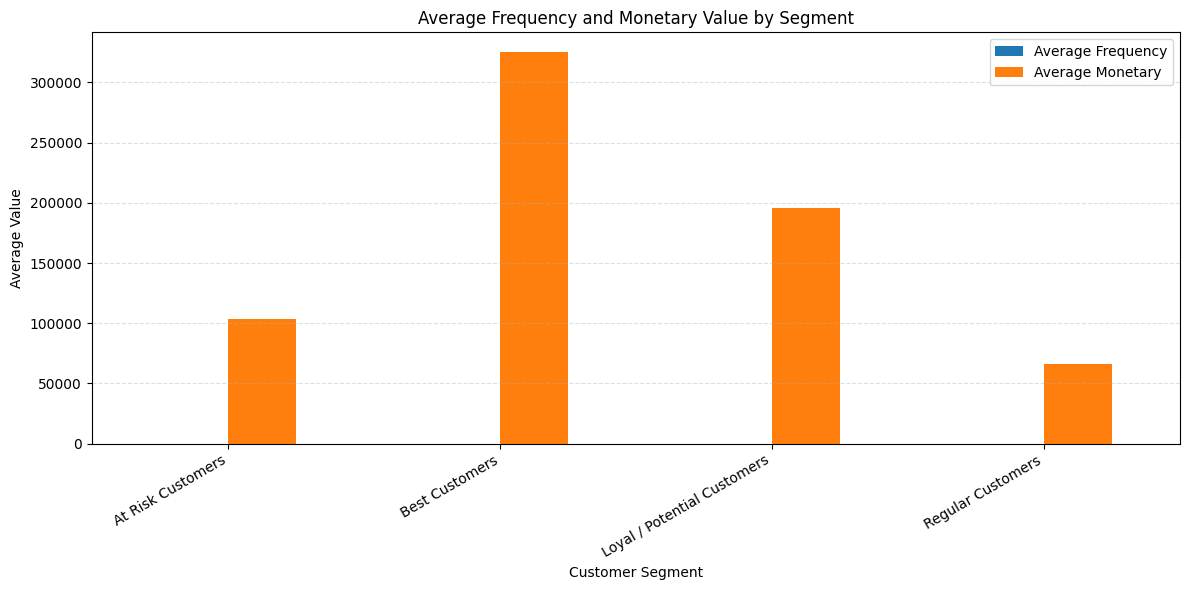

In [ ]:

# ==========================================
# STEP 21: CUSTOMER SEGMENT COMPARISON
# ==========================================

segment_summary[
    ["Average_Frequency", "Average_Monetary"]
].plot(kind="bar", figsize=(12, 6))

plt.title("Average Frequency and Monetary Value by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Value")
plt.xticks(rotation=30, ha="right")
plt.legend(["Average Frequency", "Average Monetary"])
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

TOP 10 CUSTOMERS BY TOTAL SPENDING
     Customer_ID  Recency  Frequency   Monetary   Customer_Segment
961         1973       57         10  750049.12     Best Customers
699         1708       30          8  738332.68     Best Customers
685         1694      152          7  688804.69     Best Customers
550         1557       91          7  676959.51     Best Customers
373         1379       37          9  651705.31     Best Customers
861         1871        6         10  633674.18     Best Customers
166         1171      124          7  622750.05     Best Customers
688         1697       14          9  622112.51     Best Customers
93          1095      174          4  621679.48  At Risk Customers
398         1404       13          5  610950.28     Best Customers


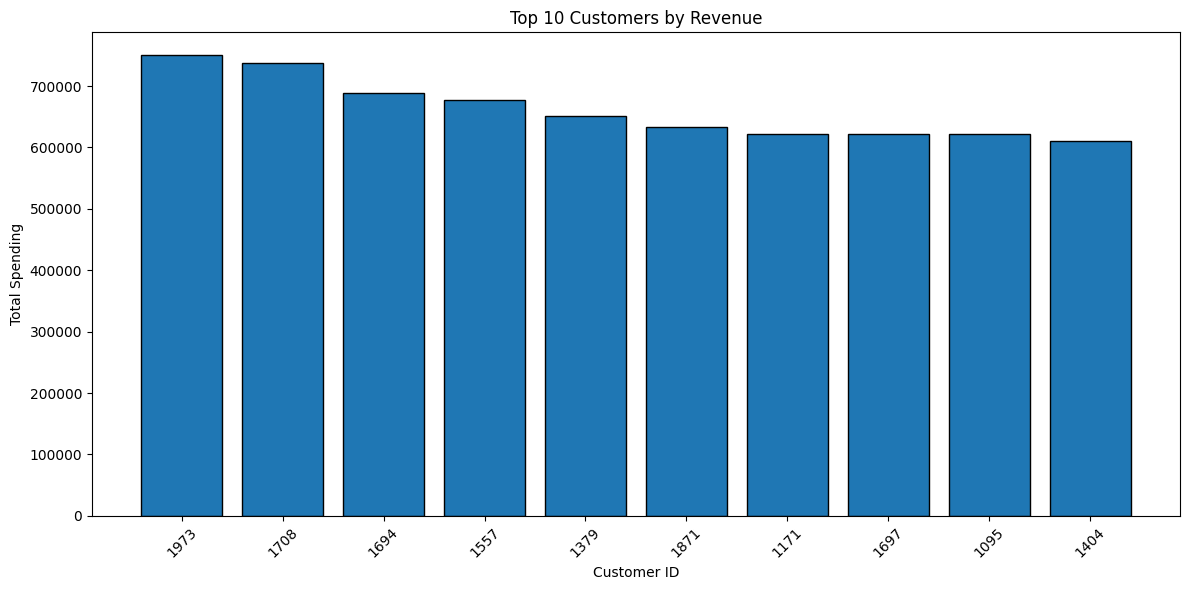

In [ ]:
# ==========================================
# STEP 22: TOP 10 HIGH-VALUE CUSTOMERS
# ==========================================

top_customers = rfm.sort_values(
    by="Monetary",
    ascending=False
).head(10)

print("TOP 10 CUSTOMERS BY TOTAL SPENDING")
print("=" * 60)

print(
    top_customers[
        ["Customer_ID", "Recency", "Frequency", "Monetary",
         "Customer_Segment"]
    ].round(2)
)

plt.figure(figsize=(12, 6))

plt.bar(
    top_customers["Customer_ID"].astype(str),
    top_customers["Monetary"],
    edgecolor="black"
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Total Spending")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

RFM SCORE DISTRIBUTION

R_Score Distribution:
R_Score
1    247
2    247
3    247
4    248
Name: count, dtype: int64

F_Score Distribution:
F_Score
1    248
2    247
3    247
4    247
Name: count, dtype: int64

M_Score Distribution:
M_Score
1    248
2    247
3    247
4    247
Name: count, dtype: int64


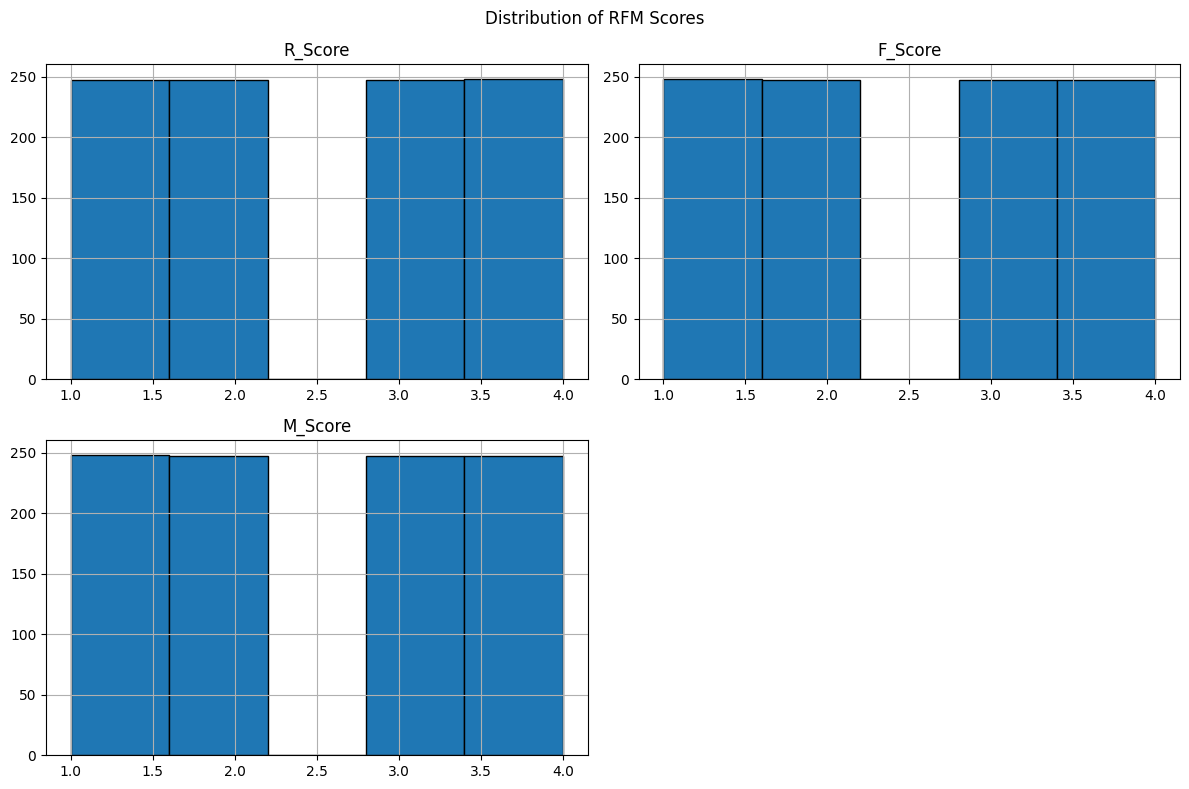

In [ ]:

# ==========================================
# STEP 23: RFM SCORE DISTRIBUTION
# ==========================================

score_columns = ["R_Score", "F_Score", "M_Score"]

print("RFM SCORE DISTRIBUTION")
print("=" * 50)

for column in score_columns:
    if column in rfm.columns:
        print(f"\n{column} Distribution:")
        print(rfm[column].value_counts().sort_index())

rfm[score_columns].hist(
    bins=5,
    figsize=(12, 8),
    edgecolor="black"
)

plt.suptitle("Distribution of RFM Scores")
plt.tight_layout()
plt.show()

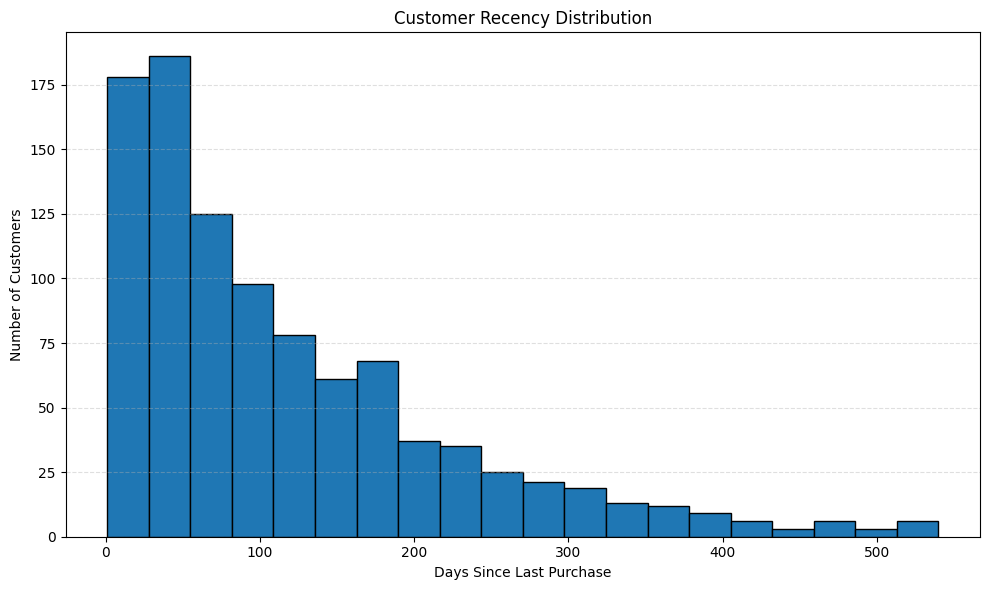

RECENCY STATISTICS
count    989.00
mean     117.19
std      107.15
min        1.00
25%       37.00
50%       83.00
75%      166.00
max      540.00
Name: Recency, dtype: float64


In [ ]:

# ==========================================
# STEP 24: CUSTOMER RECENCY ANALYSIS
# ==========================================

plt.figure(figsize=(10, 6))

plt.hist(
    rfm["Recency"],
    bins=20,
    edgecolor="black"
)

plt.title("Customer Recency Distribution")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("RECENCY STATISTICS")
print(rfm["Recency"].describe().round(2))

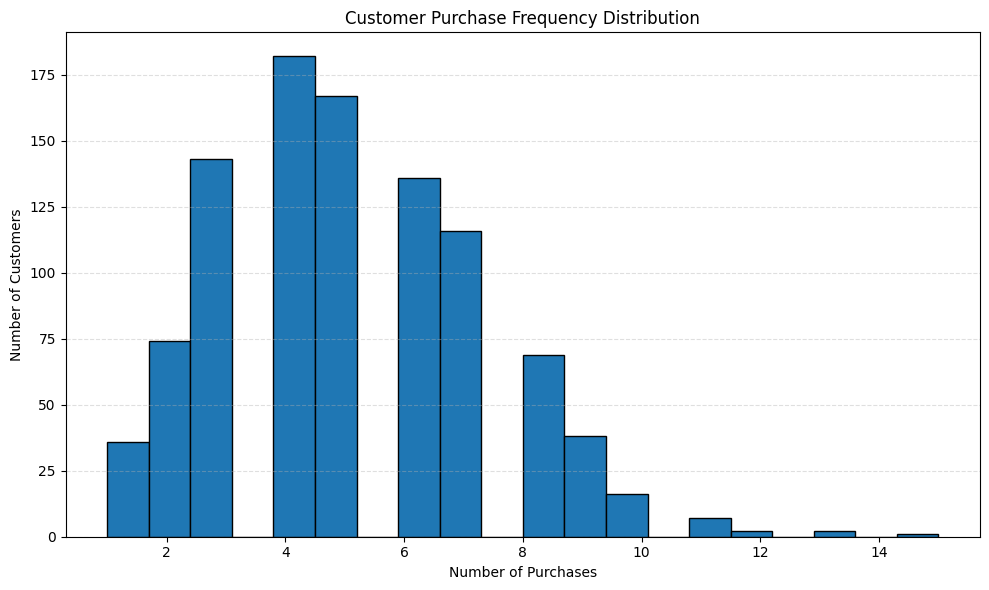

FREQUENCY STATISTICS
count    989.00
mean       5.06
std        2.20
min        1.00
25%        3.00
50%        5.00
75%        7.00
max       15.00
Name: Frequency, dtype: float64


In [ ]:

# ==========================================
# STEP 25: CUSTOMER PURCHASE FREQUENCY
# ==========================================

plt.figure(figsize=(10, 6))

plt.hist(
    rfm["Frequency"],
    bins=20,
    edgecolor="black"
)

plt.title("Customer Purchase Frequency Distribution")
plt.xlabel("Number of Purchases")
plt.ylabel("Number of Customers")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("FREQUENCY STATISTICS")
print(rfm["Frequency"].describe().round(2))

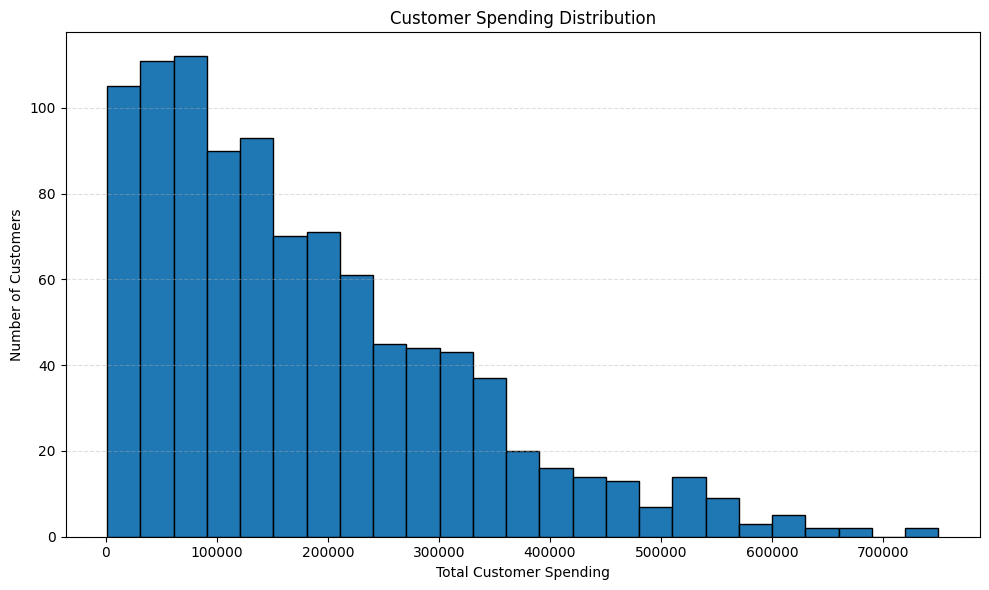

MONETARY STATISTICS
count       989.00
mean     180261.74
std      140742.97
min        1104.05
25%       71891.82
50%      146135.44
75%      263345.76
max      750049.12
Name: Monetary, dtype: float64


In [ ]:

# ==========================================
# STEP 26: CUSTOMER MONETARY ANALYSIS
# ==========================================

plt.figure(figsize=(10, 6))

plt.hist(
    rfm["Monetary"],
    bins=25,
    edgecolor="black"
)

plt.title("Customer Spending Distribution")
plt.xlabel("Total Customer Spending")
plt.ylabel("Number of Customers")
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

print("MONETARY STATISTICS")
print(rfm["Monetary"].describe().round(2))

RFM CORRELATION MATRIX
           Recency  Frequency  Monetary
Recency      1.000     -0.404    -0.204
Frequency   -0.404      1.000     0.547
Monetary    -0.204      0.547     1.000


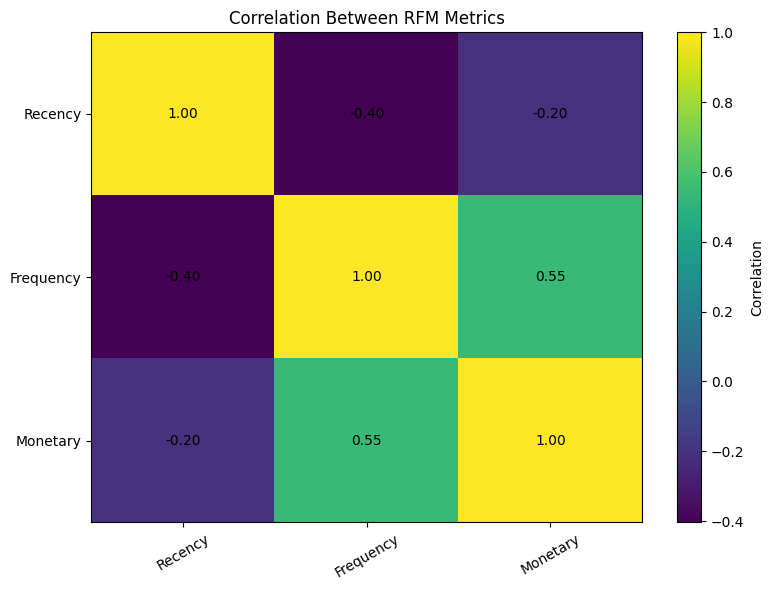

In [ ]:

# ==========================================
# STEP 27: RFM CORRELATION ANALYSIS
# ==========================================

correlation_data = rfm[
    ["Recency", "Frequency", "Monetary"]
].corr()

print("RFM CORRELATION MATRIX")
print("=" * 50)
print(correlation_data.round(3))

plt.figure(figsize=(8, 6))

plt.imshow(
    correlation_data,
    interpolation="nearest",
    aspect="auto"
)

plt.colorbar(label="Correlation")

plt.xticks(
    range(len(correlation_data.columns)),
    correlation_data.columns,
    rotation=30
)

plt.yticks(
    range(len(correlation_data.index)),
    correlation_data.index
)

for i in range(len(correlation_data)):
    for j in range(len(correlation_data.columns)):
        plt.text(
            j, i,
            f"{correlation_data.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )

plt.title("Correlation Between RFM Metrics")
plt.tight_layout()
plt.show()

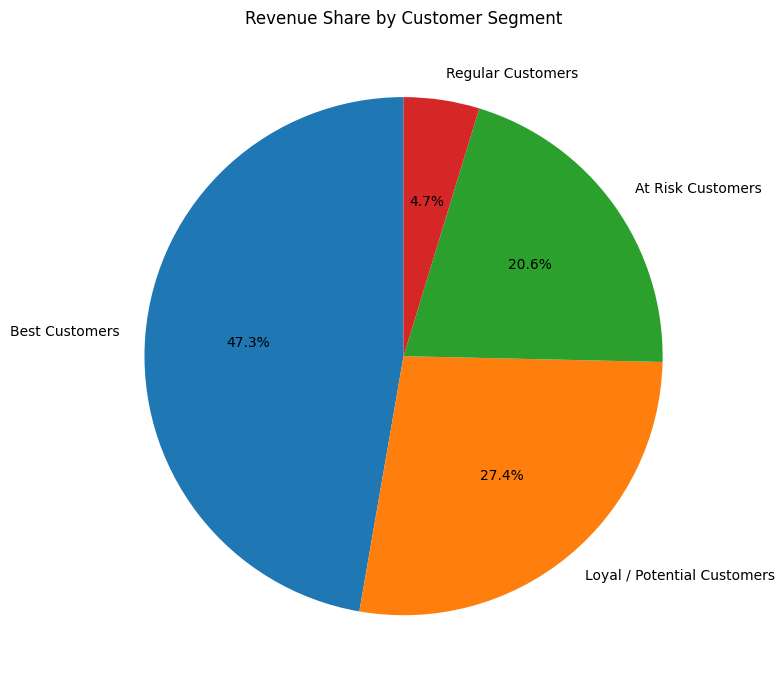

REVENUE SHARE (%)
Customer_Segment
Best Customers                 47.27
Loyal / Potential Customers    27.37
At Risk Customers              20.63
Regular Customers               4.72
Name: Monetary, dtype: float64


In [ ]:

# ==========================================
# STEP 28: CUSTOMER SEGMENT REVENUE SHARE
# ==========================================

plt.figure(figsize=(10, 7))

plt.pie(
    revenue_percentage,
    labels=revenue_percentage.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Share by Customer Segment")
plt.tight_layout()
plt.show()

print("REVENUE SHARE (%)")
print(revenue_percentage.round(2))

In [ ]:

# ==========================================
# STEP 29: AUTOMATED BUSINESS INSIGHTS
# ==========================================

print("E-COMMERCE BUSINESS INSIGHTS")
print("=" * 60)

best_segment = segment_revenue.idxmax()
best_revenue = segment_revenue.max()

print(f"\n1. Highest Revenue Segment: {best_segment}")
print(f"   Revenue Generated: {best_revenue:.2f}")

largest_segment = rfm["Customer_Segment"].value_counts().idxmax()
largest_count = rfm["Customer_Segment"].value_counts().max()

print(f"\n2. Largest Customer Segment: {largest_segment}")
print(f"   Number of Customers: {largest_count}")

highest_spending_customer = rfm.loc[
    rfm["Monetary"].idxmax()
]

print("\n3. Highest Spending Customer")
print(f"   Customer ID: {highest_spending_customer['Customer_ID']}")
print(f"   Total Spending: {highest_spending_customer['Monetary']:.2f}")

print("\n4. Average Customer Spending")
print(f"   {rfm['Monetary'].mean():.2f}")

print("\n5. Average Purchase Frequency")
print(f"   {rfm['Frequency'].mean():.2f}")

print("\n6. Average Days Since Last Purchase")
print(f"   {rfm['Recency'].mean():.2f}")

print("\nAnalysis completed successfully.")

E-COMMERCE BUSINESS INSIGHTS

1. Highest Revenue Segment: Best Customers
   Revenue Generated: 84273668.41

2. Largest Customer Segment: At Risk Customers
   Number of Customers: 354

3. Highest Spending Customer
   Customer ID: 1973
   Total Spending: 750049.12

4. Average Customer Spending
   180261.74

5. Average Purchase Frequency
   5.06

6. Average Days Since Last Purchase
   117.19

Analysis completed successfully.


In [ ]:

# ==========================================
# STEP 30: EXPORT FINAL ANALYSIS REPORT
# ==========================================

# Export detailed customer-level RFM analysis
rfm.to_csv(
    "ecommerce_customer_segmentation.csv",
    index=False
)

# Export segment-level summary
segment_summary.to_csv(
    "ecommerce_segment_summary.csv"
)

# Export revenue contribution
revenue_percentage.rename(
    "Revenue_Percentage"
).to_csv(
    "ecommerce_revenue_contribution.csv"
)

print("PROJECT REPORTS EXPORTED SUCCESSFULLY!")
print("-" * 50)
print("1. ecommerce_customer_segmentation.csv")
print("2. ecommerce_segment_summary.csv")
print("3. ecommerce_revenue_contribution.csv")

PROJECT REPORTS EXPORTED SUCCESSFULLY!
--------------------------------------------------
1. ecommerce_customer_segmentation.csv
2. ecommerce_segment_summary.csv
3. ecommerce_revenue_contribution.csv


In [ ]:

# ==========================================
# STEP 31: FINAL BUSINESS RECOMMENDATIONS
# ==========================================

print("=" * 60)
print("E-COMMERCE BUSINESS RECOMMENDATIONS")
print("=" * 60)

best_segment = segment_revenue.idxmax()
largest_segment = rfm["Customer_Segment"].value_counts().idxmax()

print("\n1. REVENUE GROWTH")
print(f"Focus on the {best_segment} segment because it generates")
print("the highest total revenue in the current analysis.")

print("\n2. CUSTOMER RETENTION")
print("Offer loyalty rewards and exclusive benefits to valuable")
print("customers to encourage repeat purchases.")

print("\n3. CUSTOMER REACTIVATION")
print("Identify customers with high Recency values and send")
print("personalized offers to encourage them to return.")

print("\n4. CUSTOMER LOYALTY")
print("Create reward programs for frequent buyers and")
print("encourage customers to purchase more often.")

print("\n5. CUSTOMER SEGMENTATION")
print(f"Monitor the {largest_segment} segment and design")
print("marketing campaigns based on customer behavior.")

print("\n6. DATA-DRIVEN DECISIONS")
print("Use RFM metrics to improve marketing strategies,")
print("customer retention, and revenue management.")

print("\n" + "=" * 60)
print("BUSINESS RECOMMENDATIONS COMPLETED")
print("=" * 60)

E-COMMERCE BUSINESS RECOMMENDATIONS

1. REVENUE GROWTH
Focus on the Best Customers segment because it generates
the highest total revenue in the current analysis.

2. CUSTOMER RETENTION
Offer loyalty rewards and exclusive benefits to valuable
customers to encourage repeat purchases.

3. CUSTOMER REACTIVATION
Identify customers with high Recency values and send
personalized offers to encourage them to return.

4. CUSTOMER LOYALTY
Create reward programs for frequent buyers and
encourage customers to purchase more often.

5. CUSTOMER SEGMENTATION
Monitor the At Risk Customers segment and design
marketing campaigns based on customer behavior.

6. DATA-DRIVEN DECISIONS
Use RFM metrics to improve marketing strategies,
customer retention, and revenue management.

BUSINESS RECOMMENDATIONS COMPLETED


In [ ]:

# ==========================================
# STEP 32: FINAL PROJECT SUMMARY
# ==========================================

print("=" * 70)
print("       E-COMMERCE CUSTOMER ANALYTICS PROJECT")
print("=" * 70)

total_customers = rfm["Customer_ID"].nunique()
total_revenue = rfm["Monetary"].sum()
average_spending = rfm["Monetary"].mean()
average_frequency = rfm["Frequency"].mean()
average_recency = rfm["Recency"].mean()

total_segments = rfm["Customer_Segment"].nunique()

print("\nPROJECT OVERVIEW")
print("-" * 70)
print(f"Total Unique Customers       : {total_customers}")
print(f"Total Revenue                : {total_revenue:.2f}")
print(f"Average Customer Spending   : {average_spending:.2f}")
print(f"Average Purchase Frequency   : {average_frequency:.2f}")
print(f"Average Recency (Days)       : {average_recency:.2f}")
print(f"Number of Customer Segments  : {total_segments}")

print("\nCUSTOMER SEGMENT COUNTS")
print("-" * 70)
print(rfm["Customer_Segment"].value_counts())

print("\nTOP REVENUE-GENERATING SEGMENT")
print("-" * 70)
print(segment_revenue.idxmax())
print(f"Revenue: {segment_revenue.max():.2f}")

print("\nKEY PROJECT OBJECTIVES")
print("-" * 70)
print("1. Analyze customer purchasing behavior.")
print("2. Calculate Recency, Frequency and Monetary metrics.")
print("3. Identify customer segments using RFM analysis.")
print("4. Visualize customer and revenue distributions.")
print("5. Generate data-driven business recommendations.")

print("\nPROJECT STATUS: ANALYSIS SUMMARY GENERATED")
print("=" * 70)

       E-COMMERCE CUSTOMER ANALYTICS PROJECT

PROJECT OVERVIEW
----------------------------------------------------------------------
Total Unique Customers       : 989
Total Revenue                : 178278858.84
Average Customer Spending   : 180261.74
Average Purchase Frequency   : 5.06
Average Recency (Days)       : 117.19
Number of Customer Segments  : 4

CUSTOMER SEGMENT COUNTS
----------------------------------------------------------------------
Customer_Segment
At Risk Customers              354
Best Customers                 259
Loyal / Potential Customers    249
Regular Customers              127
Name: count, dtype: int64

TOP REVENUE-GENERATING SEGMENT
----------------------------------------------------------------------
Best Customers
Revenue: 84273668.41

KEY PROJECT OBJECTIVES
----------------------------------------------------------------------
1. Analyze customer purchasing behavior.
2. Calculate Recency, Frequency and Monetary metrics.
3. Identify customer segments us